<a href="https://colab.research.google.com/github/MarcoIppolito96/tuia-dog-recognition-app/blob/feature%2Ftp2-razas-perros/1-pre-processing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP2 - Parte 1: dataset y preprocesamiento

Notebook de documentación y tratamiento del dataset **70 Dog Breeds Image Dataset**: análisis
exploratorio, control de calidad, conjunto independiente de evaluación, preprocesamiento,
data augmentation y splits (ver `ENUNCIADO.md`, sección 3).

Tiene que poder leerse como un informe: celdas Markdown que explican qué se hace y por qué,
código y salidas (gráficos y tablas) **ejecutadas y guardadas**. Una notebook sin salidas
visibles se considera no entregada.

Lo que produce esta notebook lo reutilizan `2-train.ipynb` y `train_classifier`: los splits
finales (CSV/JSON con rutas y etiquetas), el conjunto independiente y el preprocesamiento
encapsulado en un módulo de `src/lib/`.

**Notebook en Google Colab (si corresponde):** <reemplazar por el link, con permiso de lectura para los docentes>

Si entregan la notebook en Colab, esta copia del repositorio funciona como notebook de referencia:
el link de arriba es obligatorio y la notebook de Colab debe estar ejecutada, con sus salidas
(ver `ENUNCIADO.md`, sección 8.2).

## Equipo
- Alumno 1 :
- Alumno 2 :

## 1. Clonar el repositorio

Solo si trabajan en Colab. Si tu fork es privado, generá un token de acceso (GitHub → Settings →
Developer settings → Personal access tokens) y usalo en la URL, o subí un zip del proyecto a Colab/Drive.

In [1]:
REPO_URL = "https://github.com/MarcoIppolito96/tuia-dog-recognition-app.git"

# Siempre parte de /content: si se vuelve a correr, no clona adentro de otro clon
%cd /content
!git clone -b feature/tp2-razas-perros $REPO_URL proyecto
%cd /content/proyecto

/content
fatal: destination path 'proyecto' already exists and is not an empty directory.
/content/proyecto


## 2. Instalar dependencias

Colab ya incluye torch, torchvision, opencv, numpy, scikit-learn y matplotlib;
solo se instala lo que falta.

In [2]:
!pip install -q pydantic-settings python-dotenv kagglehub albumentations onnxruntime

## 3. Configuración del entorno

En Colab no hay PostgreSQL, por lo que se desactiva pgvector y se usa la base vectorial JSON.
La configuración se define por variables de entorno **antes** de importar `lib`.

In [3]:
import os
import sys
from pathlib import Path

os.environ["USE_PGVECTOR"] = "false"
# Ajustá acá cualquier otra variable (IMAGE_SIZE, EMBEDDING_DIM, paths, etc.)

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from lib.config import settings

import torch
print("dataset_path:", settings.dataset_path)
print("GPU disponible:", torch.cuda.is_available())

dataset_path: data/dataset
GPU disponible: True


## 4. Descargar el dataset

In [4]:
!python scripts/download_dataset.py
!ls data/dataset

Descargando gpiosenka/70-dog-breedsimage-data-set ...
Using Colab cache for faster access to the '70-dog-breedsimage-data-set' dataset.
Dataset disponible en /content/proyecto/data/dataset
dogs.csv  test	train  valid


## 5. Descripción del dataset

TO-DO:
- Cantidad de razas, imágenes por raza en cada split, formato, resolución y licencia de uso.
- Cómo están encuadradas las imágenes, comparado con los recortes de YOLO que va a recibir el
  clasificador en la Etapa 3.
- Limitaciones del dataset (razas parecidas, sesgos, etc.) y cómo pueden afectar los resultados.

### Recuento general del dataset
Recorremos las carpetas `train/`, `valid/` y `test/` y armamos una tabla con una fila por imagen
(split, raza y ruta). Con esa tabla contamos razas e imágenes por split, y leemos el encabezado de
cada archivo para conocer formato, resolución y modo de color, y detectar archivos que no abren.

In [5]:
import pandas as pd
from PIL import Image

# Una fila por imagen: split, raza y ruta
SPLITS = ["train", "valid", "test"]
filas = []
for split in SPLITS:
    for ruta in sorted((settings.dataset_path / split).glob("*/*")):
        filas.append({"split": split, "raza": ruta.parent.name, "ruta": str(ruta)})
df = pd.DataFrame(filas)

print("Cantidad de razas:", df["raza"].nunique())
print(df["split"].value_counts(), "\n")

# Imágenes por raza en cada split (estadísticas)
conteo = df.pivot_table(index="raza", columns="split", values="ruta", aggfunc="count")
display(conteo.describe().round(1))

# Lee solo el encabezado de cada imagen (rápido): formato, tamaño y modo de color
def info_imagen(ruta):
    try:
        with Image.open(ruta) as im:
            return im.format, im.width, im.height, im.mode
    except Exception:
        return None, None, None, None  # archivo que no abre

df[["formato", "ancho", "alto", "modo"]] = df["ruta"].apply(lambda r: pd.Series(info_imagen(r)))
print(df["formato"].value_counts(dropna=False), "\n")
print(df["modo"].value_counts(dropna=False), "\n")
print("Resoluciones más comunes:\n", df[["ancho", "alto"]].value_counts().head())
print("\nArchivos que no abren:", df["formato"].isna().sum())

# El dataset trae un CSV con rutas y etiquetas: vemos qué columnas tiene
display(pd.read_csv(settings.dataset_path / "dogs.csv").head())

Cantidad de razas: 71
split
train    7946
valid     700
test      700
Name: count, dtype: int64 



split,test,train,valid
count,70.0,70.0,70.0
mean,10.0,113.5,10.0
std,0.0,24.7,0.0
min,10.0,65.0,10.0
25%,10.0,99.0,10.0
50%,10.0,111.5,10.0
75%,10.0,125.0,10.0
max,10.0,198.0,10.0


formato
JPEG    9346
Name: count, dtype: int64 

modo
RGB    9346
Name: count, dtype: int64 

Resoluciones más comunes:
 ancho  alto
224    224     9346
Name: count, dtype: int64

Archivos que no abren: 0


,filepaths,labels,data set
0,train/Afghan/001.jpg,Afghan,train
1,train/Afghan/002.jpg,Afghan,train
2,train/Afghan/003.jpg,Afghan,train
3,train/Afghan/004.jpg,Afghan,train
4,train/Afghan/005.jpg,Afghan,train


**Resultado.**
- 9.346 imágenes: 7.946 en `train`, 700 en `valid` y 700 en `test`.
- En `train` hay entre 65 y 198 imágenes por raza (mediana 111,5): desbalance de ~3 a 1, moderado.
- `valid` y `test` tienen exactamente **10 imágenes por raza**. Es poco: con 10 imágenes, cada error
  mueve 10 puntos la accuracy de esa raza, así que las métricas por raza serían inestables.
  Lo tenemos en cuenta al definir los splits (sección 11).
- Todas son JPEG, RGB y de **224×224**: ya vienen redimensionadas, coinciden con el `IMAGE_SIZE` de
  los modelos y no hay imágenes en escala de grises ni archivos corruptos.
- Aparecen 71 nombres de raza aunque cada split tiene 70 (se analiza a continuación).

In [6]:
# ¿Qué raza no aparece en los tres splits? (71 nombres en total, 70 por split)
razas_por_split = {s: set(df.loc[df["split"] == s, "raza"]) for s in SPLITS}
todas = set(df["raza"])
for raza in sorted(todas):
    faltan = [s for s in SPLITS if raza not in razas_por_split[s]]
    if faltan:
        print(f"{raza!r}: no está en {faltan} | imágenes: {df[df['raza'] == raza]['split'].value_counts().to_dict()}")

'American  Spaniel': no está en ['train', 'test'] | imágenes: {'valid': 10}
'American Spaniel': no está en ['valid'] | imágenes: {'train': 89, 'test': 10}


### Inconsistencia en los nombres de raza
El dataset reporta 71 nombres de raza pero cada split tiene 70. La carpeta de `valid` se llama
`American  Spaniel` (dos espacios) y en `train`/`test` `American Spaniel`. Es la misma raza: sin
corregirlo, sus 10 imágenes de validación quedarían como una clase inexistente en entrenamiento.
Se corrige normalizando los espacios en la etiqueta (no renombrando carpetas), para que el arreglo
sea reproducible al volver a descargar el dataset.

In [7]:
# Corrección: unifica espacios repetidos en el nombre de la raza ('American  Spaniel' → 'American Spaniel')
df["raza"] = df["raza"].str.split().str.join(" ")
print("\nRazas tras normalizar los nombres:", df["raza"].nunique())
print(df.pivot_table(index="raza", columns="split", values="ruta", aggfunc="count").loc["American Spaniel"])


Razas tras normalizar los nombres: 70
split
test     10
train    89
valid    10
Name: American Spaniel, dtype: int64


### Encuadre de las imágenes vs. recortes de YOLO
En la Etapa 3 el clasificador no va a recibir la foto completa: YOLO detecta cada perro y le pasa
el **recorte** de su caja. Si el modelo se entrena con fotos donde el perro ocupa poco espacio y
después recibe recortes donde ocupa todo, ve imágenes distintas a las que aprendió (*cambio de
dominio*). Para medir cuánto difieren, corremos el mismo YOLO y la misma configuración de la app
sobre 300 imágenes de `train` al azar y medimos:
- **qué fracción de la imagen ocupa el perro** (área de la caja / área de la imagen): cerca de 1
  significa que la foto ya está recortada al perro, como el recorte de YOLO;
- **cuántos perros detecta por imagen**: 0 puede indicar una foto sin perro visible y más de 1,
  una foto con varios perros. Ambos casos se revisan en el control de calidad.

In [8]:
!pip install -q ultralytics

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


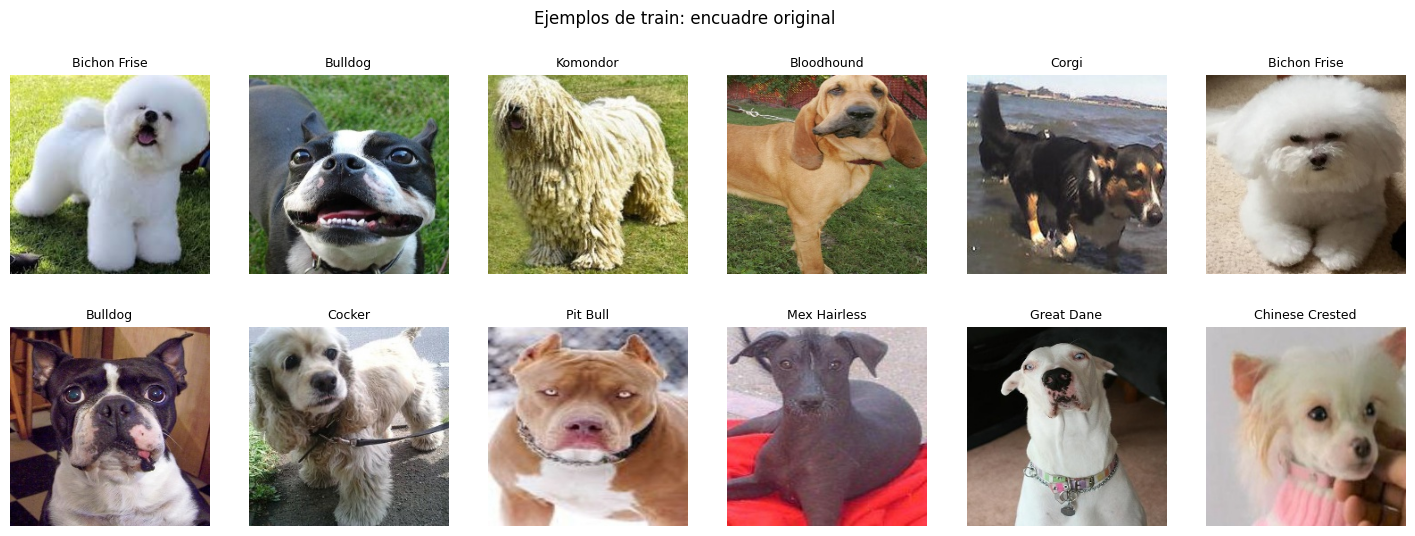

Perros detectados por imagen (muestra de 300):
perros_detectados
0    141
1    155
2      4
Name: count, dtype: int64

Fracción del área ocupada por el perro: mediana 0.89, p10 0.67, p90 0.97


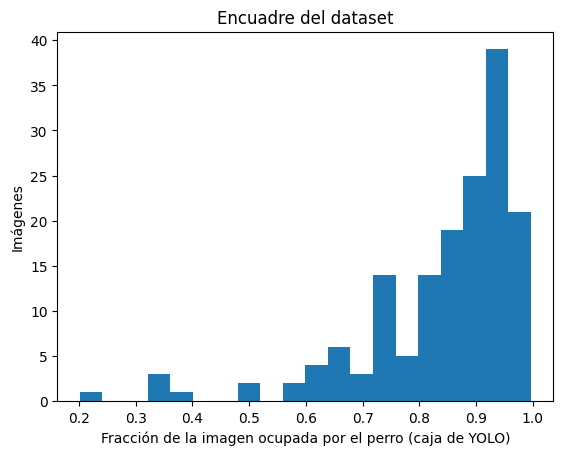

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO

muestra = df[df["split"] == "train"].sample(300, random_state=42).reset_index(drop=True)

# Grilla de 12 imágenes al azar para ver el encuadre original
fig, ejes = plt.subplots(2, 6, figsize=(18, 6))
for eje, (_, fila) in zip(ejes.ravel(), muestra.head(12).iterrows()):
    eje.imshow(Image.open(fila["ruta"])); eje.set_title(fila["raza"], fontsize=9); eje.axis("off")
plt.suptitle("Ejemplos de train: encuadre original"); plt.show()

# Mismo detector y configuración que usará la app (Etapa 3)
detector = YOLO(settings.yolo_model)
cantidades, fracciones = [], []
for ruta in muestra["ruta"]:
    r = detector(ruta, classes=[settings.yolo_dog_class_id], conf=settings.yolo_conf_threshold, verbose=False)[0]
    cajas = r.boxes.xyxy.cpu().numpy()
    cantidades.append(len(cajas))
    if len(cajas):
        # Fracción de la imagen que ocupa el perro más grande
        areas = (cajas[:, 2] - cajas[:, 0]) * (cajas[:, 3] - cajas[:, 1])
        fracciones.append(areas.max() / (r.orig_shape[0] * r.orig_shape[1]))
muestra["perros_detectados"] = cantidades

print("Perros detectados por imagen (muestra de 300):")
print(muestra["perros_detectados"].value_counts().sort_index())
print(f"\nFracción del área ocupada por el perro: mediana {np.median(fracciones):.2f}, "
      f"p10 {np.percentile(fracciones, 10):.2f}, p90 {np.percentile(fracciones, 90):.2f}")

plt.hist(fracciones, bins=20)
plt.xlabel("Fracción de la imagen ocupada por el perro (caja de YOLO)"); plt.ylabel("Imágenes")
plt.title("Encuadre del dataset"); plt.show()

**Resultado.**
- Cuando YOLO detecta al perro, este ocupa casi toda la imagen: mediana 89% del área (p10 67%,
  p90 97%). Las fotos ya están encuadradas sobre el perro, parecidas a un recorte de YOLO, por lo
  que el cambio de dominio por encuadre entre el dataset y la Etapa 3 es chico.
- YOLO no detectó perros en 141 de 300 imágenes (47%). En la grilla se ven primeros planos donde el
  perro llena la imagen y queda cortado; YOLO fue entrenado con escenas completas (COCO) y le cuesta
  reconocer un perro sin contexto. Por eso no se puede usar YOLO directamente para descartar
  imágenes "sin perro" (se analiza a continuación).
- 4 imágenes tienen 2 perros detectados.
- Observación: las dos imágenes etiquetadas "Bulldog" de la grilla parecen Boston Terrier o Bulldog
  Francés: posible ruido de etiquetas, a revisar en el EDA.

### ¿Por qué YOLO no encuentra al perro en la mitad de las imágenes?
Hipótesis: el perro ocupa toda la imagen y aparece cortado, así que al detector le falta contexto.
Probamos sobre las imágenes sin detección: (a) agregar un borde gris alrededor de la foto, para que
el perro quede "dentro" de una escena, y (b) bajar el umbral de confianza de 0,25 a 0,10.

Imágenes sin detección: 141
  Recuperadas con borde (conf 0.25): 74
  Recuperadas con conf 0.10 (sin borde): 43


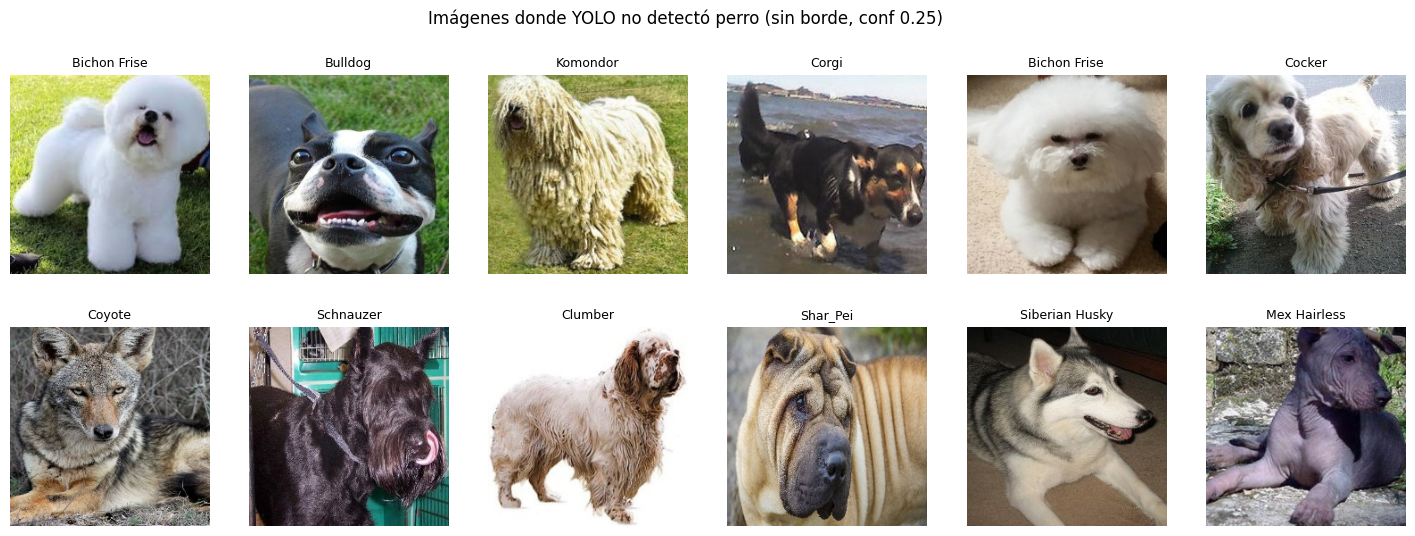

In [10]:
import cv2

# Agrega un borde gris (25% del lado) para darle contexto al detector
def con_borde(ruta, frac=0.25):
    img = cv2.imread(ruta)  # BGR, el formato que ultralytics espera en arrays
    b = int(img.shape[0] * frac)
    return cv2.copyMakeBorder(img, b, b, b, b, cv2.BORDER_CONSTANT, value=(114, 114, 114))

def detecta(imagen, conf):
    r = detector(imagen, classes=[settings.yolo_dog_class_id], conf=conf, verbose=False)[0]
    return len(r.boxes) > 0

sin_det = muestra[muestra["perros_detectados"] == 0]
con_borde_ok = sum(detecta(con_borde(r), settings.yolo_conf_threshold) for r in sin_det["ruta"])
conf_baja_ok = sum(detecta(r, 0.10) for r in sin_det["ruta"])
print(f"Imágenes sin detección: {len(sin_det)}")
print(f"  Recuperadas con borde (conf {settings.yolo_conf_threshold}): {con_borde_ok}")
print(f"  Recuperadas con conf 0.10 (sin borde): {conf_baja_ok}")

# Grilla de imágenes donde YOLO no encontró perro
fig, ejes = plt.subplots(2, 6, figsize=(18, 6))
for eje, (_, fila) in zip(ejes.ravel(), sin_det.head(12).iterrows()):
    eje.imshow(Image.open(fila["ruta"])); eje.set_title(fila["raza"], fontsize=9); eje.axis("off")
plt.suptitle("Imágenes donde YOLO no detectó perro (sin borde, conf 0.25)"); plt.show()

**Resultado.**
- De las 141 imágenes sin detección, el borde recupera 74 y bajar la confianza a 0,10 recupera 43:
  el borde ayuda más, porque le da contexto al detector.
- Quedan 67 sin detección, y en la grilla hay perros completos y bien visibles (Bichon Frise,
  Komondor, Corgi): el perro cortado no explica todos los casos.
- Una de las "razas" del dataset es Coyote, que no es un perro: es esperable que YOLO no lo detecte
  como `dog`, y es una limitación del dataset a tener en cuenta.

### ¿YOLO ve otra cosa en lugar de un perro?
Nueva hipótesis: YOLO detecta al animal pero lo asigna a otra clase de COCO (por ejemplo, `sheep`
para perros blancos y lanudos). Corremos YOLO sin filtrar por clase sobre las 141 imágenes y
contamos qué clase predice con más confianza en cada una.

In [11]:
from collections import Counter

# Sin filtrar por clase: ¿qué ve YOLO donde no encontró un perro?
clases_vistas = Counter()
for ruta in sin_det["ruta"]:
    r = detector(ruta, conf=settings.yolo_conf_threshold, verbose=False)[0]
    if len(r.boxes):
        mejor = int(r.boxes.conf.argmax())  # la detección con mayor confianza
        clases_vistas[r.names[int(r.boxes.cls[mejor])]] += 1
    else:
        clases_vistas["(nada)"] += 1
print(clases_vistas.most_common())

[('(nada)', 33), ('cat', 29), ('bear', 18), ('sheep', 12), ('cow', 10), ('horse', 9), ('person', 7), ('giraffe', 6), ('teddy bear', 6), ('bird', 3), ('elephant', 2), ('sandwich', 2), ('donut', 2), ('bed', 1), ('truck', 1)]


**Resultado.** Sin filtrar por clase, YOLO detecta algo en 108 de las 141 imágenes: casi siempre
otro animal (cat 29, bear 18, sheep 12, cow 10, horse 9, giraffe 6, teddy bear 6, entre otros);
solo en 33 no detecta nada. Es decir, encuentra al animal pero lo confunde de especie, sobre todo
en primeros planos de baja resolución (224×224) sin contexto.

**Decisiones:**
- **Control de calidad:** YOLO no se usa para descartar imágenes "sin perro" del dataset, porque
  eliminaría cerca del 47% de imágenes válidas.
- **Etapa 3:** se mantiene el filtro por la clase `dog` (16). Aceptar otras clases recuperaría
  perros, pero introduciría falsos positivos: `cat` es la confusión más frecuente y el sistema
  debe devolver cero perros ante una foto de un gato. Queda documentado como limitación: en
  primeros planos o imágenes de baja resolución el detector puede no encontrar al perro.

### Resumen de la sección 5: descripción y limitaciones del dataset

**Descripción.** *70 Dog Breeds Image Dataset* (Kaggle, autor gpiosenka), licencia **CC0: Public
Domain** (uso libre, sin restricciones). 70 razas, 9.346 imágenes JPEG RGB de 224×224:
7.946 en `train` (65 a 198 por raza), 700 en `valid` y 700 en `test` (10 por raza).

**Encuadre.** Las fotos están centradas en el perro, que ocupa en promedio casi el 90% de la
imagen: se parecen a los recortes que YOLO entregará al clasificador en la Etapa 3, por lo que el
cambio de dominio por encuadre es chico. Las fotos reales que reciba la app (escenas completas,
otra resolución, varios perros) sí pueden diferir; eso se mide con el conjunto independiente.

**Limitaciones y cómo pueden afectar los resultados.**
- **Validación y test chicos** (10 imágenes por raza): las métricas por raza son poco estables.
- **Desbalance moderado** (~3:1 en `train`): el modelo puede favorecer las razas con más fotos.
- **Razas muy parecidas entre sí** y **posible ruido de etiquetas** (por ejemplo, fotos de "Bulldog"
  que parecen Boston Terrier o Bulldog Francés): limitan la accuracy alcanzable y generan
  confusiones sistemáticas entre ciertos pares.
- **Solo 70 razas y sin mestizos:** un perro de otra raza o mestizo siempre será asignado a alguna
  de las 70; de ahí la importancia del umbral `"unknown"`.
- **"Coyote" no es un perro:** el detector de la Etapa 3 no lo reconocerá como `dog`.
- **Sesgo de origen web:** fotos mayormente de un solo perro, de frente y bien iluminadas; el
  rendimiento puede bajar con fotos tomadas en otras condiciones.
- **Resolución fija y baja (224×224):** contribuye a que YOLO confunda la especie en primeros planos.

## 6. Análisis exploratorio (EDA)

TO-DO:
- Distribución de clases: imágenes por raza en cada split (gráfico y estadísticas). Desbalance.
- Resoluciones, relación de aspecto, canales, formatos y archivos corruptos.
- Grilla de ejemplos por raza, incluyendo pares de razas fáciles de confundir.
- Variaciones: iluminación, pose, fondo, oclusiones y cantidad de perros por imagen.

In [ ]:
## TO-DO: análisis exploratorio del dataset.

## 7. Control de calidad y filtrado

TO-DO: reglas explícitas y reproducibles (archivos corruptos, baja resolución, imágenes borrosas o
con exposición extrema, duplicados y casi-duplicados dentro y entre splits, imágenes mal etiquetadas).
Reportar cuántas imágenes descarta cada regla y mostrar ejemplos de descartes.

In [ ]:
## TO-DO: reglas de filtrado, conteo de descartes por regla y ejemplos.

## 8. Conjunto independiente de evaluación

TO-DO: imágenes que no pertenezcan al dataset (internet o fotos propias), con las mismas razas que
las carpetas del dataset. Incluir imágenes con un perro (Etapas 1 y 2), escenas con varios perros u
otros objetos e imágenes sin perros (Etapa 3). Documentar fuente y licencia; no subirlas al repositorio.

In [ ]:
## TO-DO: construcción y resumen del conjunto independiente (por ejemplo, en data/dataset/independent/<raza>/).

## 9. Preprocesamiento

TO-DO: definir y justificar el resize, la normalización y el orden de canales (la app entrega BGR).

⚠️ El mismo preprocesamiento debe usarse en las notebooks y en los servicios de la app:
encapsulalo en un módulo de `src/lib/` e importalo desde ambos lados.

In [ ]:
## TO-DO: transformaciones de preprocesamiento (importadas desde el módulo compartido).

## 10. Data augmentation

TO-DO: horizontal flip, rotación, blur, variaciones de brillo y contraste y ruido, con sus rangos
justificados. Mostrar una grilla de ejemplos aumentados de una misma imagen. Solo sobre `train`.

In [ ]:
## TO-DO: pipeline de data augmentation con ejemplos visuales.

## 11. Splits

TO-DO: definir train / validation / test (los del dataset o redefinidos, justificando), verificar
que no haya fuga de datos entre splits, fijar semillas y guardar los splits finales (CSV/JSON con
rutas y etiquetas) para `2-train.ipynb`.

In [ ]:
## TO-DO: splits finales, verificación de fuga de datos y exportación.

## 12. Resumen final

TO-DO: tabla con la cantidad de razas e imágenes por split, incluido el conjunto independiente.

In [ ]:
## TO-DO: tabla resumen.

## 13. Licencias y uso de imágenes

TO-DO: licencia del dataset, fuente y licencia de las imágenes del conjunto independiente y criterio
aplicado a imágenes con personas identificables.